# Packet tests of 2026-10-12: how traces and images change with the operating parameters

Data: `data/2026-10-12-PA03_PQ04_Packet_Tests/`, the first run with **varied operating parameters**.
Five settings were taken one after the other. For each, there are 3 trace sets (4 channels of board
101, about 33 s apart) and then a synchronized image of boards 101 and 102 (50×130×500, 20×20
binning). The last setting has no finished image.

This notebook:

1. reads the settings from the `.meta` files and finds the groups and what changed between them;
2. checks the trace setup and quality;
3. computes all 85 trace features (`src/trace_features.py`) for every trace;
4. compares every pair of settings, feature by feature and channel by channel, against the scatter
   between the 3 trace sets of each setting;
5. shows the features and waveforms that change most;
6. looks at the images (overscan level and noise, charge per bin);
7. summarises what changed with each parameter.

Key figures are also saved to `docs/context/figures/` (prefix `oct12_`).

In [1]:
import sys, json, itertools
from pathlib import Path
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt

PROJECT = Path.cwd().parent
sys.path.insert(0, str(PROJECT / "src"))
from trace_features import trace_features, FEATURES, scalar_names
from decode_trace import decode_trace

RUN = PROJECT / "data" / "2026-10-12-PA03_PQ04_Packet_Tests"
FIGS = PROJECT / "docs" / "context" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
def save(fig, name):
    fig.savefig(FIGS / f"oct12_{name}.png", dpi=120, bbox_inches="tight")
print(RUN.name, "|", len(list(RUN.iterdir())), "files")

2026-10-12-PA03_PQ04_Packet_Tests | 378 files


## 1. The settings

Every acquisition's `.meta` lists all voltages and sequencer constants. The groups are found
automatically: consecutive acquisitions with the same voltages form one group. The table lists
every parameter that differs from group 1 (the reference).

In [2]:
metas = sorted(((json.loads(p.read_text()), p) for p in RUN.glob("*.meta")), key=lambda x: x[0]["DATEini"])
VOLTAGES = [k for k in metas[0][0] if k[:2] in ("V1", "V2", "V3", "H1", "H2", "H3", "TG", "SW", "OG", "RG", "DG")
            or k in ("VSUB", "VDD1", "VDD2", "VDRAIN1", "VDRAIN2", "VR1", "VR2")]
TIMING = ["delay_Va", "delay_Vb", "delay_Ha", "delay_Hb", "delay_Hc", "delayInt", "delayRGL", "delayRGH",
          "delaySWH", "delaySWL", "delayOGL", "delayOGH", "delayDGL", "delayDGH"]
def signature(m):
    return json.dumps({k: m.get(k) for k in VOLTAGES + TIMING})

groups, current, sig = [], None, None             # groups of board 101 acquisitions
for m, p in metas:
    if m["ACMID"] != 101:
        continue
    s = signature(m)
    if s != sig:
        current = {"settings": {k: m.get(k) for k in VOLTAGES + TIMING}, "files": []}
        groups.append(current); sig = s
    current["files"].append((m, p))
ref = groups[0]["settings"]
NAMES = []
for g, group in enumerate(groups, start=1):
    changes = {k: (ref[k], v) for k, v in group["settings"].items() if v != ref[k]}
    t0, t1 = group["files"][0][0]["DATEini"][11:19], group["files"][-1][0]["DATEini"][11:19]
    kinds = sorted({p.name.split("_")[0] for _, p in group["files"]})
    short = "ref" if not changes else ", ".join(sorted({k.split("_")[0] + ("_" + k.split("_")[1] if k.startswith(("H3", "TG")) else "") for k in changes}))
    NAMES.append(f"{g}: {short}")
    print(f"group {g}  {t0}-{t1}  {len(group['files']):2d} acquisitions {kinds}")
    for k, (a, b) in changes.items():
        print(f"      {k:8s} {a} -> {b}")

group 1  18:56:04-19:03:32  13 acquisitions ['img', 'trace']
group 2  19:15:03-19:19:48  13 acquisitions ['img', 'trace']
      VDD1     -19.014416 -> -20.524341
      VDD2     -19.014416 -> -20.524341
group 3  20:40:40-20:43:57  13 acquisitions ['img', 'trace']
      V1_B_L   7.7 -> 7.2
      V2_C_L   7.9 -> 7.4
      V3_B_L   7.7 -> 7.2
      TG_B_H   7.4 -> 7.0
      V1_A_L   7.9 -> 7.4
      V3_A_L   7.9 -> 7.4
      TG_A_H   7.4 -> 7.0
      TG_A_L   7.4 -> 7.0
group 4  20:59:52-21:02:40  13 acquisitions ['img', 'trace']
      H1_B_L   6.5 -> 6.0
      H2_C_L   6.7 -> 6.2
      H3_B_L   6.5 -> 6.0
      H1_A_L   6.7 -> 6.2
      H3_A_L   6.7 -> 6.2
group 5  21:09:20-21:15:32  13 acquisitions ['img', 'trace']
      H3_A_L   6.7 -> 6.2


Group names used below: group 2 = VDD; group 3 = vertical low rails and transfer gate; group 4 =
horizontal low rails; group 5 = H3_A_L only. Three things to note:

* **VDD went back to −19 V after group 2.** Groups 3, 4 and 5 each differ from the reference only in
  the listed rails, so every comparison of group 2 with groups 3–5 also contains the VDD change back.
  The clean single-change comparisons are 3 vs 4 / 3 vs 5 (V+TG and H) and **4 vs 5** (four H low
  rails only);

* in group 3 on board 101, **TG_B_H = 7.0 V is below TG_B_L = 7.4 V** (board 102 has 7.0/7.0);
* the VDD values are read back from the board (−20.52 for a requested −20.5).

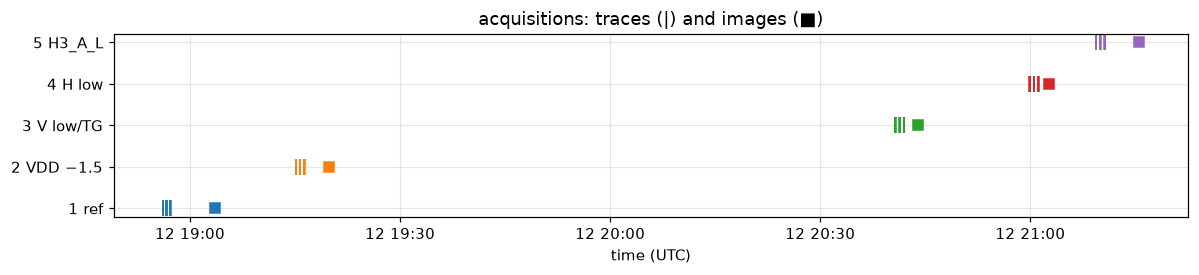

In [3]:
LABEL = {1: "1 ref", 2: "2 VDD −1.5", 3: "3 V low/TG", 4: "4 H low", 5: "5 H3_A_L"}
fig, ax = plt.subplots(figsize=(11, 2.6))
for g, group in enumerate(groups, start=1):
    for m, p in group["files"]:
        t = datetime.fromisoformat(m["DATEini"])
        kind = p.name.split("_")[0]
        ax.plot(t, g, "|" if kind == "trace" else "s", color=f"C{g - 1}", ms=10 if kind == "trace" else 7)
ax.set(yticks=list(LABEL), yticklabels=list(LABEL.values()), xlabel="time (UTC)", title="acquisitions: traces (|) and images (■)")
plt.tight_layout(); plt.show()

## 2. Trace setup and quality

The traces use `take_trace.py`, which does not set the cuts. They therefore inherit the cuts of the
last image.

In [4]:
traces = []
for g, group in enumerate(groups, start=1):
    for m, p in group["files"]:
        if p.name.startswith("trace"):
            ch = int(p.name.split("_ch")[1][0])
            data = p.with_suffix(f".RJ45ADCDATA{ch}")
            duration = (datetime.fromisoformat(m["DATEend"]) - datetime.fromisoformat(m["DATEini"])).total_seconds()
            traces.append(dict(group=g, ch=ch, path=data, meta=m, NCOLPRE=m["NCOLPRE"], BOOLCLR=m["BOOLCLR"],
                               seconds=duration, mb=data.stat().st_size / 1e6))
from collections import Counter
print("group, NCOLPRE, BOOLCLR, duration (s), size (MB) -> number of traces")
for k, n in sorted(Counter((t["group"], t["NCOLPRE"], t["BOOLCLR"], round(t["seconds"], 1), round(t["mb"])) for t in traces).items()):
    print("  ", k, "->", n)

group, NCOLPRE, BOOLCLR, duration (s), size (MB) -> number of traces
   (1, 0, 0, 0.8, 12) -> 12
   (2, 185, 0, 1.7, 68) -> 12
   (3, 185, 0, 1.7, 68) -> 12
   (4, 185, 0, 1.7, 68) -> 12
   (5, 185, 0, 1.7, 68) -> 12


**Group 1 traces were read with `NCOLPRE = 0`. All later traces have `NCOLPRE = 185`**, inherited
from the first image. Each row of a later trace first skips 3,700 columns (3,720 horizontal transfers
before each row-start pixel), so the trace takes 1.7 s instead of 0.8 s. **Group 1 is therefore not
directly comparable with groups 2–5**: any difference may come from the trace setup. Groups 2–5
share the same setup and are compared with each other. Group 1 is shown in grey.

## 3. Features of every trace

`trace_features` on all 60 traces (about one minute). A trace with lost data is refused.

In [5]:
names = scalar_names()
for t in traces:
    try:
        f = trace_features(t["path"], meta=t["meta"])
        t["features"] = f.scalars
        t["curves"] = f.curves
        t["warnings"] = f.info["region_warnings"]
    except ValueError as err:
        t["refused"] = str(err)[:90]
refused = [t for t in traces if "refused" in t]
print(len(traces), "traces;", len(refused), "refused:")
for t in refused:
    print("  ", t["path"].name, "-", t["refused"])
print("\nwarnings (layout vs .meta):", Counter(w for t in traces for w in t.get("warnings", [])))

60 traces; 1 refused:
   trace_2x5x500_20x20_ch3_101_20261012_211002_91.RJ45ADCDATA3 - trace has quality problems: ['1 pedestal windows have an unusual length', 'inline sums dif

warnings (layout vs .meta): Counter({'horizontal-transfer edges per pixel [20, 3720], .meta says NSBIN = 20': 45, 'horizontal-transfer edges per pixel [20, 3710, 3720], .meta says NSBIN = 20': 1, 'horizontal-transfer edges per pixel [20, 3717, 3720], .meta says NSBIN = 20': 1})


The warning confirms the inherited prescan: the row-start pixels are preceded by 3,720 horizontal
transfers instead of `NSBIN = 20`. The features use the usable pixels (not row starts), so they are
unaffected by the count itself. They can still be affected by the longer trace, which changes the
timing and the charge collected.

In [6]:
def values(group, ch, name):
    return np.array([t["features"][name] for t in traces if t["group"] == group and t["ch"] == ch and "features" in t])

def separation(a, b):
    # |mean difference| / pooled standard deviation of the repeats (NaN when undefined)
    a, b = a[np.isfinite(a)], b[np.isfinite(b)]
    if len(a) < 2 or len(b) < 2:
        return np.nan
    pooled = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return abs(a.mean() - b.mean()) / pooled if pooled > 0 else np.nan

PAIRS = [(2, 3), (2, 4), (2, 5), (3, 4), (3, 5), (4, 5), (1, 2)]
def changed(a, b):
    sa, sb = groups[a - 1]["settings"], groups[b - 1]["settings"]
    return ", ".join(f"{k} {sa[k]}→{sb[k]}" for k in sa if sa[k] != sb[k] and k[:3] not in ("VDD",)) + \
           (f", VDD {sa['VDD1']:.2f}→{sb['VDD1']:.2f}" if sa["VDD1"] != sb["VDD1"] else "")
for a, b in PAIRS:
    print(f"{a} vs {b}: {changed(a, b)[:150]}")

2 vs 3: V1_B_L 7.7→7.2, V2_C_L 7.9→7.4, V3_B_L 7.7→7.2, TG_B_H 7.4→7.0, V1_A_L 7.9→7.4, V3_A_L 7.9→7.4, TG_A_H 7.4→7.0, TG_A_L 7.4→7.0, VDD -20.52→-19.01
2 vs 4: H1_B_L 6.5→6.0, H2_C_L 6.7→6.2, H3_B_L 6.5→6.0, H1_A_L 6.7→6.2, H3_A_L 6.7→6.2, VDD -20.52→-19.01
2 vs 5: H3_A_L 6.7→6.2, VDD -20.52→-19.01
3 vs 4: V1_B_L 7.2→7.7, V2_C_L 7.4→7.9, V3_B_L 7.2→7.7, TG_B_H 7.0→7.4, V1_A_L 7.4→7.9, V3_A_L 7.4→7.9, TG_A_H 7.0→7.4, TG_A_L 7.0→7.4, H1_B_L 6.5→6.0, H2_C_L
3 vs 5: V1_B_L 7.2→7.7, V2_C_L 7.4→7.9, V3_B_L 7.2→7.7, TG_B_H 7.0→7.4, V1_A_L 7.4→7.9, V3_A_L 7.4→7.9, TG_A_H 7.0→7.4, TG_A_L 7.0→7.4, H3_A_L 6.7→6.2
4 vs 5: H1_B_L 6.0→6.5, H2_C_L 6.2→6.7, H3_B_L 6.0→6.5, H1_A_L 6.2→6.7
1 vs 2: , VDD -19.01→-20.52


## 4. Every feature, every pair of settings, every channel

**Separation = |difference of the means| / pooled scatter between the 3 trace sets.** With 3 against
3 sets, a separation of 6 corresponds to about p = 0.002 for one feature, so about 0.2 of the 85
features would pass by chance in each comparison. Note that the settings were taken 10–85 minutes
apart, so slow drift adds to the differences.

The heatmaps show log₁₀(separation) for all 85 features (rows) and the 7 comparisons (columns),
one panel per channel.

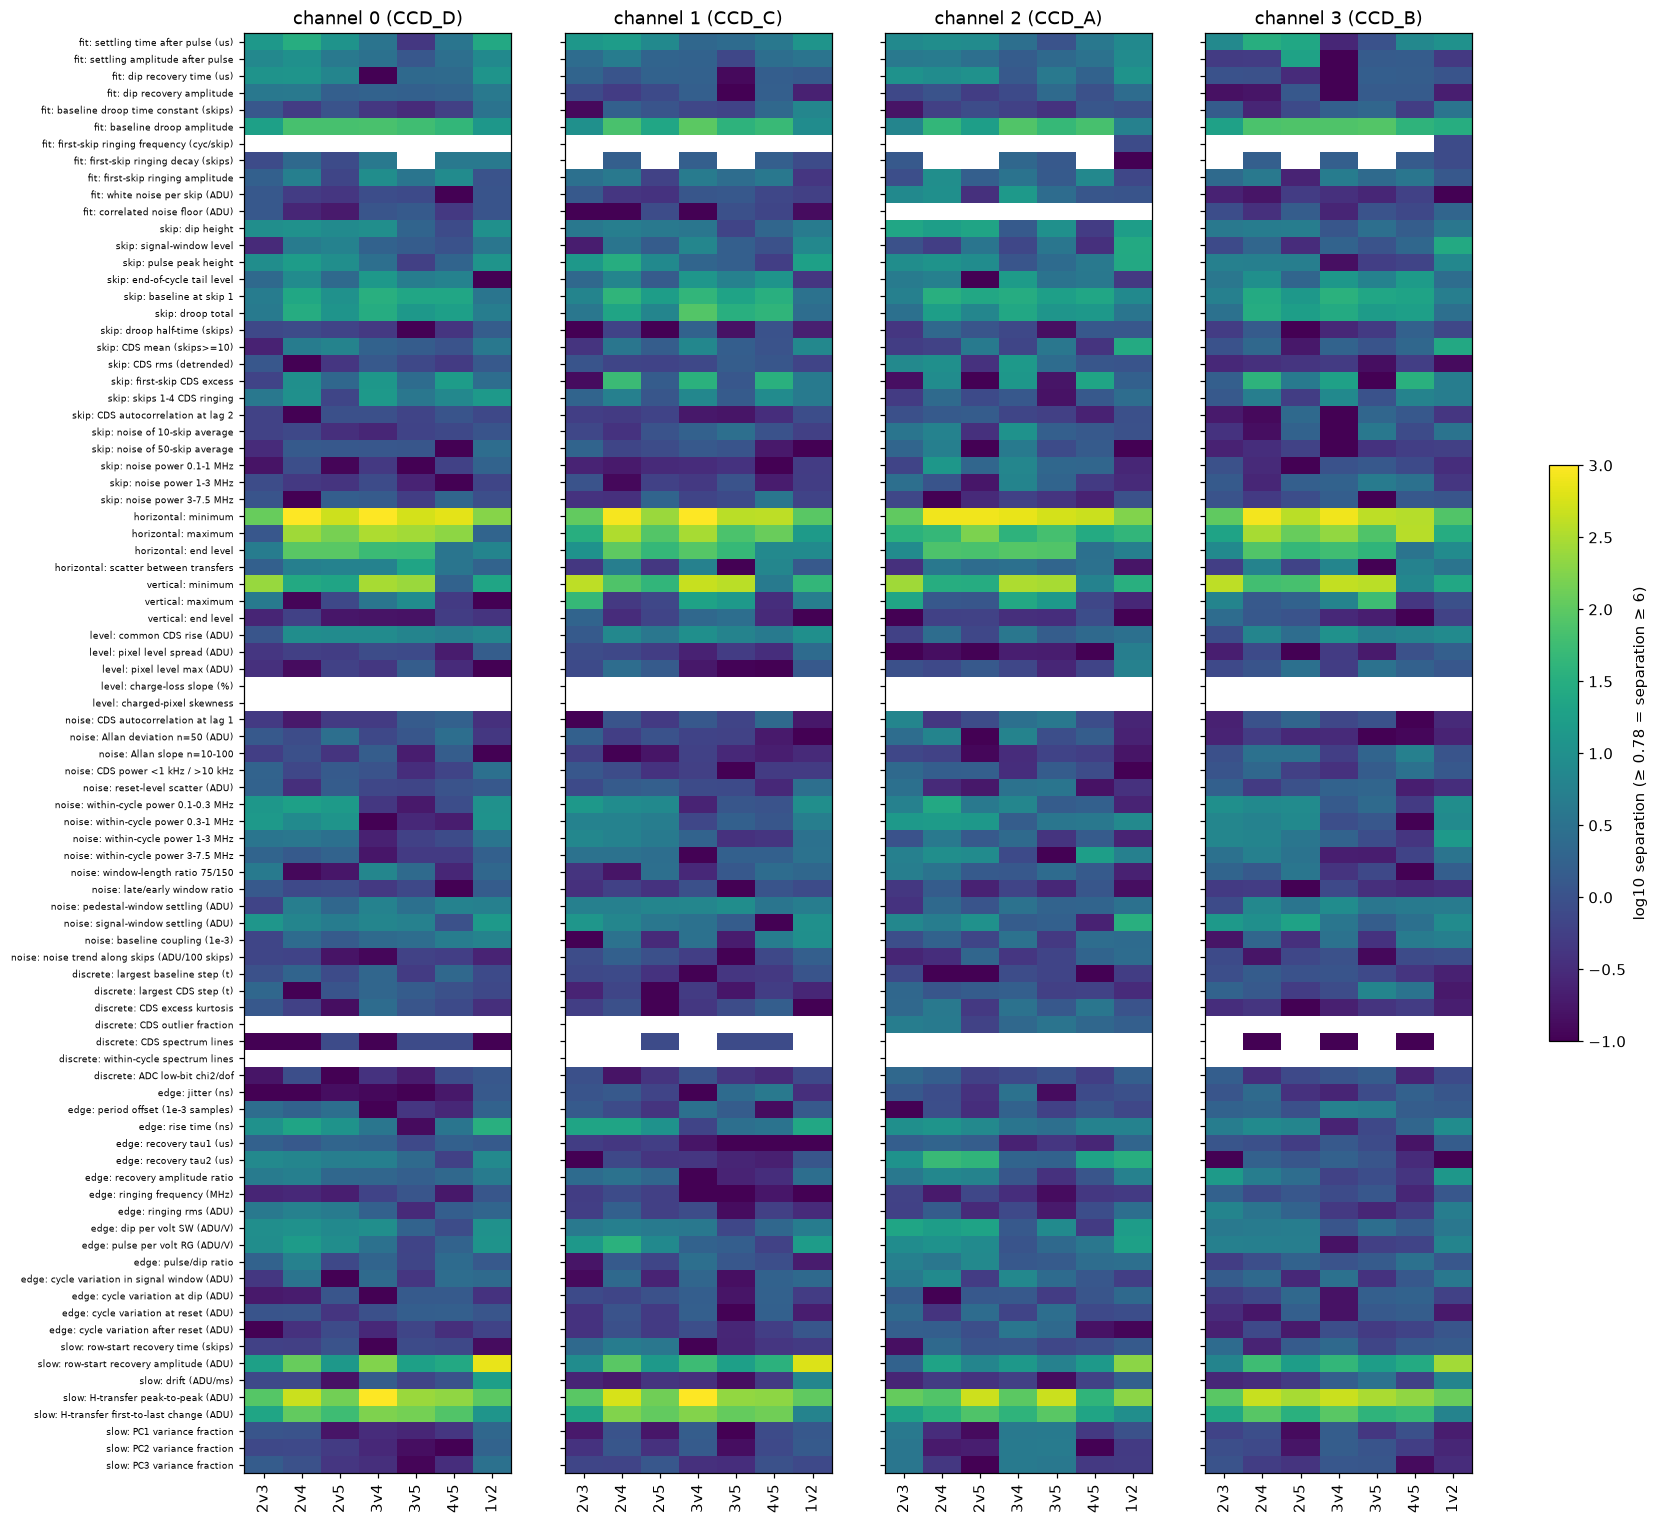

In [7]:
S = np.full((4, len(names), len(PAIRS)), np.nan)
for ch in range(4):
    for j, (a, b) in enumerate(PAIRS):
        for i, n in enumerate(names):
            S[ch, i, j] = separation(values(a, ch, n), values(b, ch, n))
fig, axes = plt.subplots(1, 4, figsize=(18, 17), sharey=True)
for ch, ax in enumerate(axes):
    im = ax.imshow(np.log10(np.clip(S[ch], 0.1, 1e3)), aspect="auto", cmap="viridis", vmin=-1, vmax=3)
    ax.set_xticks(range(len(PAIRS))); ax.set_xticklabels([f"{a}v{b}" for a, b in PAIRS], rotation=90)
    ax.set_title(f"channel {ch} ({traces[0]['meta'].get(f'ch{ch}')})")
    ax.grid(False)
axes[0].set_yticks(range(len(names))); axes[0].set_yticklabels(names, fontsize=6)
cb = fig.colorbar(im, ax=axes, shrink=0.4, label="log10 separation (≥ 0.78 = separation ≥ 6)")
save(fig, "separation_heatmap"); plt.show()

In [8]:
print("number of features with separation ≥ 6, per comparison and channel")
print(f"{'comparison':10s} {'what changed':70s}  ch0 ch1 ch2 ch3")
for j, (a, b) in enumerate(PAIRS):
    counts = [int(np.nansum(S[ch, :, j] >= 6)) for ch in range(4)]
    print(f"{a} vs {b}     {changed(a, b)[:70]:70s}  " + " ".join(f"{c:3d}" for c in counts))

number of features with separation ≥ 6, per comparison and channel
comparison what changed                                                            ch0 ch1 ch2 ch3
2 vs 3     V1_B_L 7.7→7.2, V2_C_L 7.9→7.4, V3_B_L 7.7→7.2, TG_B_H 7.4→7.0, V1_A_L   18  17  21  16
2 vs 4     H1_B_L 6.5→6.0, H2_C_L 6.7→6.2, H3_B_L 6.5→6.0, H1_A_L 6.7→6.2, H3_A_L   26  19  29  20
2 vs 5     H3_A_L 6.7→6.2, VDD -20.52→-19.01                                        21  16  23  16
3 vs 4     V1_B_L 7.2→7.7, V2_C_L 7.4→7.9, V3_B_L 7.2→7.7, TG_B_H 7.0→7.4, V1_A_L   19  18  21  17
3 vs 5     V1_B_L 7.2→7.7, V2_C_L 7.4→7.9, V3_B_L 7.2→7.7, TG_B_H 7.0→7.4, V1_A_L   13  13  12  12
4 vs 5     H1_B_L 6.0→6.5, H2_C_L 6.2→6.7, H3_B_L 6.0→6.5, H1_A_L 6.2→6.7           11  13  13  14
1 vs 2     , VDD -19.01→-20.52                                                      23  20  19  21


**Reading:** every comparison moves 10–30 features per channel. Comparisons that change different
parameters move different features, which is what makes the features useful for learning:

* the horizontal rails move the horizontal-transfer features;
* the vertical rails and TG move the vertical-transfer features;
* VDD moves the amplifier's time constants.

The next sections show which features these are.

In [9]:
def top_features(a, b, k=8):
    # features separated on all 4 channels, ranked by the median separation over the channels
    j = PAIRS.index((a, b))
    allc = np.all(S[:, :, j] >= 6, axis=0)
    med = np.array([np.nanmedian(col) if np.isfinite(col).any() else -1 for col in S[:, :, j].T])
    order = np.argsort(-med)
    return [i for i in order if allc[i]][:k]

for a, b in [(2, 4), (4, 5), (2, 3), (2, 5)]:
    print(f"\n{a} vs {b} ({changed(a, b)[:90]}): features separated on all 4 channels")
    for i in top_features(a, b):
        delta = [np.nanmean(values(b, ch, names[i])) - np.nanmean(values(a, ch, names[i])) for ch in range(4)]
        print(f"   {names[i]:46s} median separation {np.nanmedian(S[:, i, PAIRS.index((a, b))]):7.1f}   change "
              + ", ".join(f"{d:+.3g}" for d in delta))


2 vs 4 (H1_B_L 6.5→6.0, H2_C_L 6.7→6.2, H3_B_L 6.5→6.0, H1_A_L 6.7→6.2, H3_A_L 6.7→6.2, VDD -20.52): features separated on all 4 channels
   horizontal: minimum                            median separation   871.2   change -1.38e+04, -1.36e+04, -1.34e+04, -1.32e+04
   slow: H-transfer peak-to-peak (ADU)            median separation   466.7   change +8.87e+03, +1.07e+04, +1.12e+04, +1.11e+04
   horizontal: maximum                            median separation   282.3   change -5.44e+03, -3.25e+03, -2.74e+03, -2.4e+03
   slow: H-transfer first-to-last change (ADU)    median separation   100.9   change +6.44e+03, +6.57e+03, +6.99e+03, +5.1e+03
   horizontal: end level                          median separation    88.2   change -390, -425, -378, -416
   slow: row-start recovery amplitude (ADU)       median separation    76.5   change -4.7e+03, -4.39e+03, -4.21e+03, -4.5e+03
   fit: baseline droop amplitude                  median separation    70.1   change -2.37e+03, -2.34e+03, -2.32e+03,

## 5. The features that respond, setting by setting

Mean over the 3 trace sets with the scatter between them (error bars), for each setting and channel.
Group 1 (grey) was taken with a different trace setup.

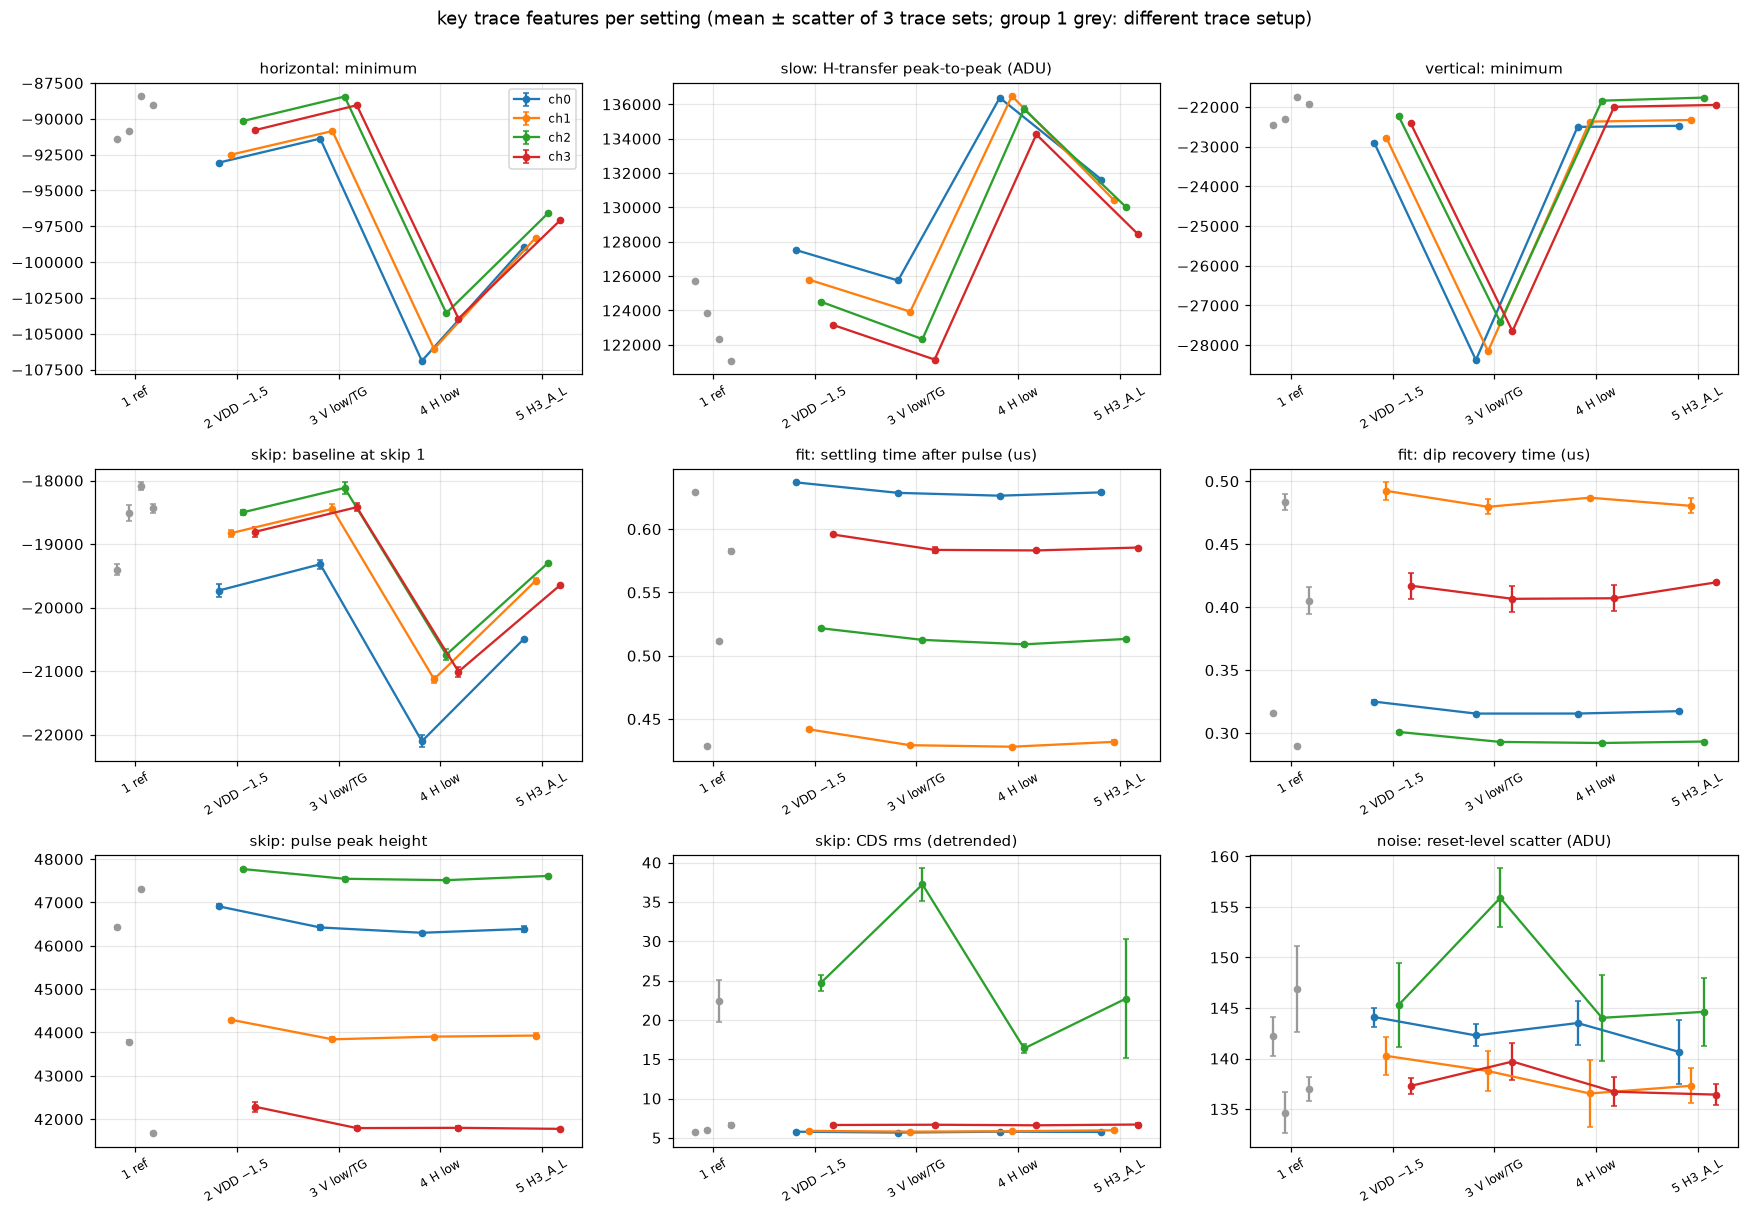

In [10]:
KEY = ["horizontal: minimum", "slow: H-transfer peak-to-peak (ADU)", "vertical: minimum", "skip: baseline at skip 1",
       "fit: settling time after pulse (us)", "fit: dip recovery time (us)", "skip: pulse peak height",
       "skip: CDS rms (detrended)", "noise: reset-level scatter (ADU)"]
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, name in zip(axes.ravel(), KEY):
    for ch in range(4):
        means = [np.nanmean(values(g, ch, name)) for g in range(1, 6)]
        sds = [np.nanstd(values(g, ch, name), ddof=1) for g in range(1, 6)]
        x = np.arange(1, 6) + (ch - 1.5) * 0.12
        ax.errorbar(x[1:], means[1:], sds[1:], fmt="o-", ms=4, capsize=2, label=f"ch{ch}", color=f"C{ch}")
        ax.errorbar(x[:1], means[:1], sds[:1], fmt="o", ms=4, capsize=2, color="0.6")
    ax.set_xticks(range(1, 6)); ax.set_xticklabels([LABEL[g] for g in range(1, 6)], rotation=30, fontsize=8)
    ax.set_title(name, fontsize=10)
axes[0, 0].legend(fontsize=8)
fig.suptitle("key trace features per setting (mean ± scatter of 3 trace sets; group 1 grey: different trace setup)", y=1.0)
plt.tight_layout(); save(fig, "key_features"); plt.show()

Because the amplifiers differ, the same feature has different levels on different channels. To see
the *change* caused by each setting, here is each feature relative to group 2, divided by the
scatter between trace sets (i.e. the signed separation). Values beyond ±6 are clear changes.
Remember that groups 3–5 all have VDD back at −19 V: a change that is **the same for 3, 4 and 5**
(e.g. the time constants) is the VDD effect; what differs between them is the rail change.

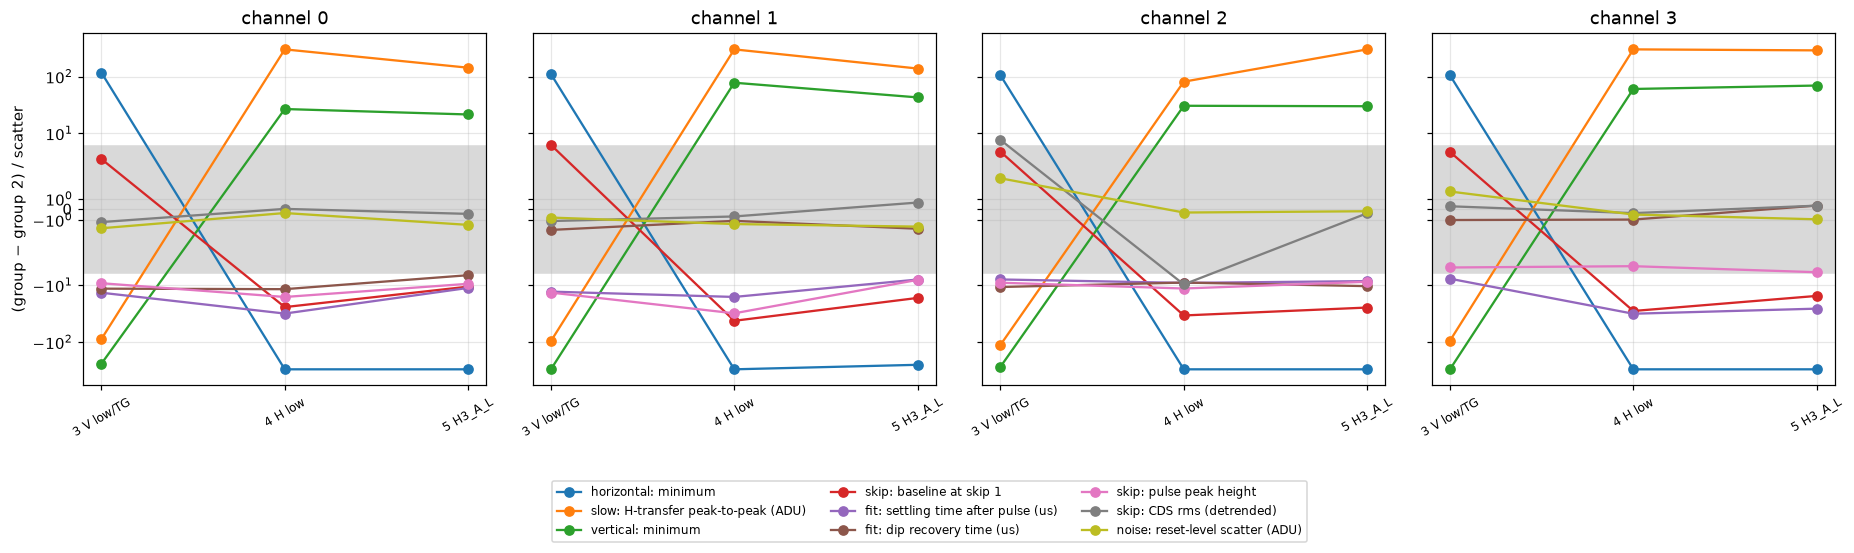

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
for ax, ch in zip(axes, range(4)):
    for k, name in enumerate(KEY):
        base = values(2, ch, name)
        z = []
        for g in (3, 4, 5):
            v = values(g, ch, name)
            pooled = np.sqrt((base.var(ddof=1) + v.var(ddof=1)) / 2)
            z.append((v.mean() - base.mean()) / pooled if pooled > 0 else np.nan)
        ax.plot([3, 4, 5], np.clip(z, -300, 300), "o-", label=name if ch == 0 else None)
    ax.axhspan(-6, 6, color="0.85"); ax.set_yscale("symlog", linthresh=6)
    ax.set_xticks([3, 4, 5]); ax.set_xticklabels([LABEL[g] for g in (3, 4, 5)], rotation=30, fontsize=8)
    ax.set_title(f"channel {ch}")
axes[0].set_ylabel("(group − group 2) / scatter")
fig.legend(loc="lower center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.2))
plt.tight_layout(); save(fig, "signed_changes"); plt.show()

## 6. The waveforms themselves

The mean horizontal transfer, the mean vertical transfer and the mean skip cycle (curves from
`trace_features`), averaged over the 3 trace sets, for groups 2–5 on channel 0. Below each panel is
the difference from group 2.

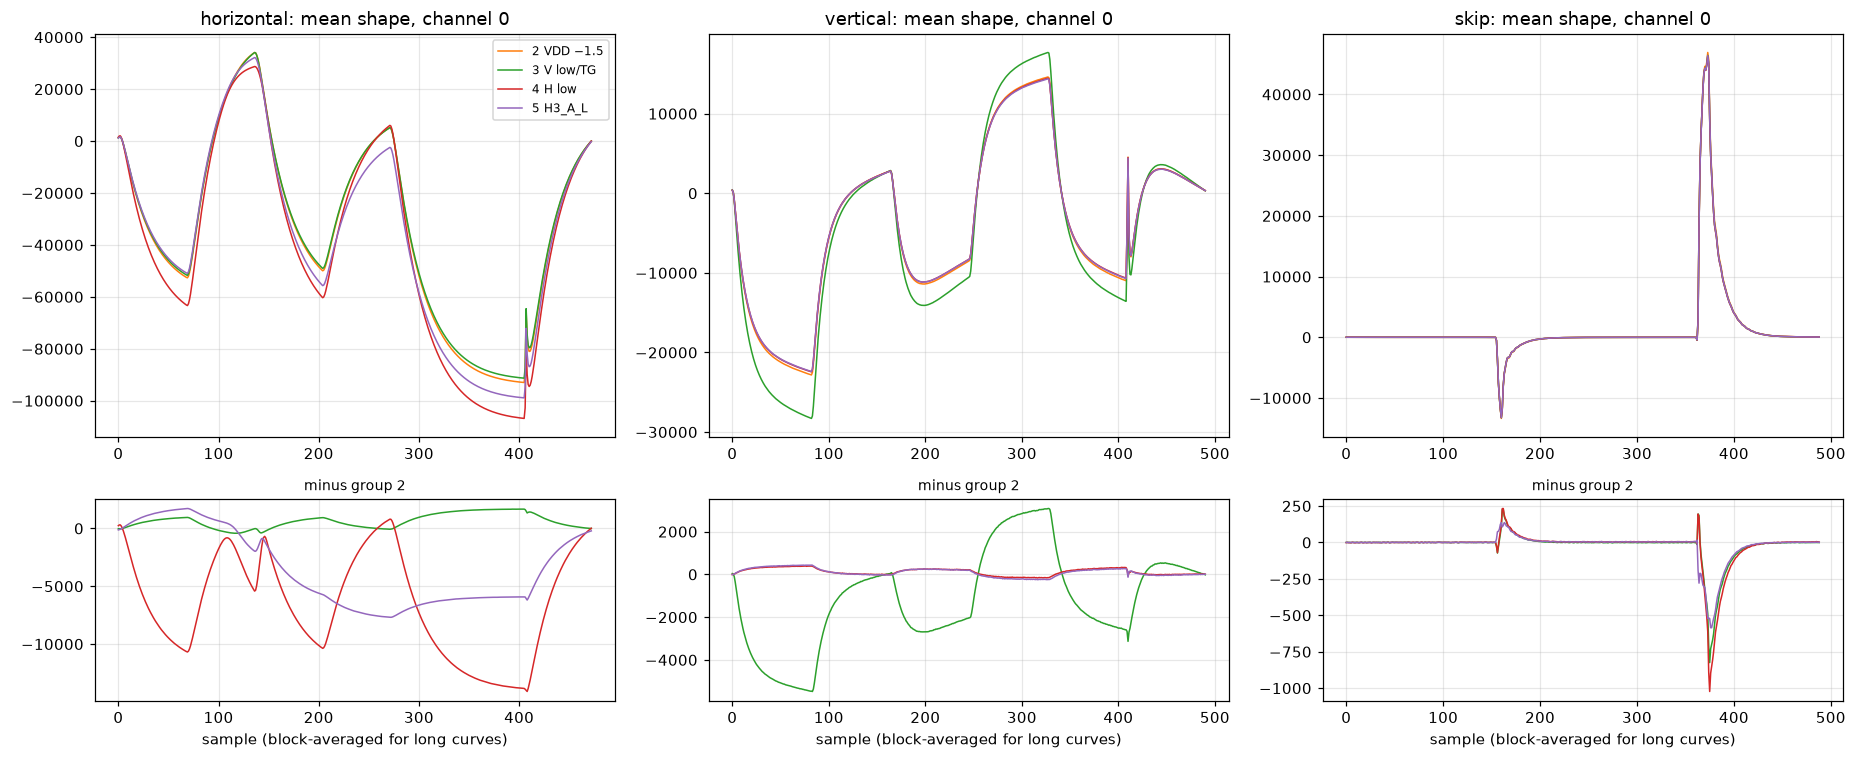

In [12]:
def mean_curve(group, ch, name):
    curves = [t["curves"][name] for t in traces if t["group"] == group and t["ch"] == ch and "curves" in t and name in t["curves"]]
    return np.mean(curves, axis=0) if curves else None

fig, axes = plt.subplots(2, 3, figsize=(17, 7), gridspec_kw={"height_ratios": [2, 1]})
for col, name in enumerate(["horizontal: mean shape", "vertical: mean shape", "skip: mean shape"]):
    ref_curve = mean_curve(2, 0, name)
    for g in (2, 3, 4, 5):
        c = mean_curve(g, 0, name)
        axes[0, col].plot(c, lw=1, label=LABEL[g], color=f"C{g - 1}")
        if g != 2:
            axes[1, col].plot(c - ref_curve, lw=1, color=f"C{g - 1}")
    axes[0, col].set_title(f"{name}, channel 0"); axes[1, col].set_title("minus group 2", fontsize=9)
    axes[1, col].set_xlabel("sample (block-averaged for long curves)")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); save(fig, "waveforms_ch0"); plt.show()

* **Horizontal transfer**: lowering all horizontal low rails (group 4) deepens the transfer waveform;
  lowering only H3_A_L (group 5) changes only the part driven by that phase.
* **Vertical transfer**: the vertical/TG change (group 3) changes the shape strongly.
* **Skip cycle**: the shape stays almost the same. The changes are in the details (time constants,
  levels), which is why the fitted features are needed.

## 7. Noise per channel

The CDS noise per skip and the noise of 50-skip averages. They drive σe in the image.

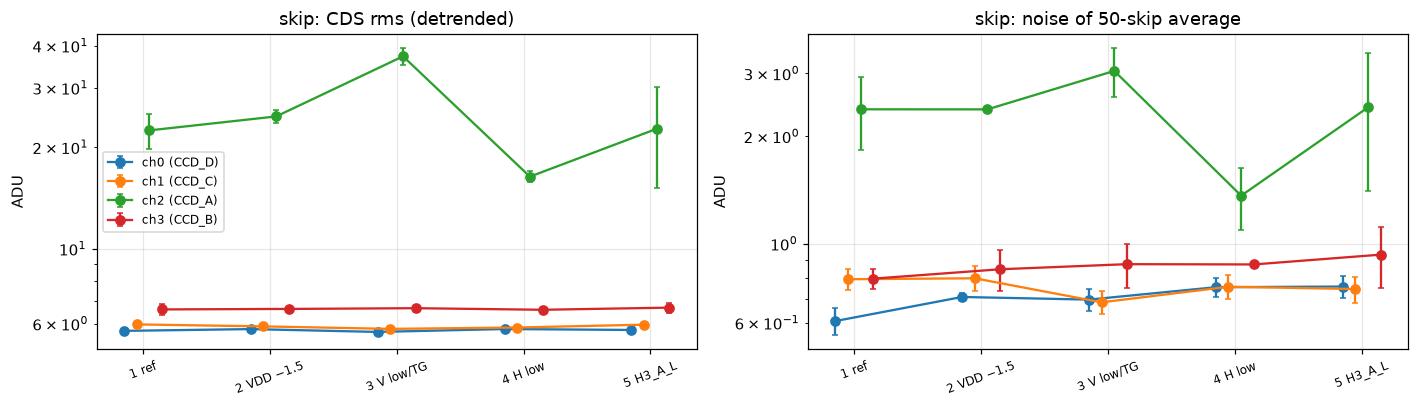

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, name in zip(axes, ["skip: CDS rms (detrended)", "skip: noise of 50-skip average"]):
    for ch in range(4):
        means = [np.nanmean(values(g, ch, name)) for g in range(1, 6)]
        sds = [np.nanstd(values(g, ch, name), ddof=1) for g in range(1, 6)]
        ax.errorbar(np.arange(1, 6) + (ch - 1.5) * 0.1, means, sds, fmt="o-", capsize=2, label=f"ch{ch} ({traces[0]['meta'].get(f'ch{ch}')})")
    ax.set_xticks(range(1, 6)); ax.set_xticklabels([LABEL[g] for g in range(1, 6)], rotation=20, fontsize=8)
    ax.set(title=name, ylabel="ADU"); ax.set_yscale("log")
axes[0].legend(fontsize=8)
plt.tight_layout(); save(fig, "trace_noise"); plt.show()

Channel 2 (amplifier A) is several times noisier than the others at every setting, and much noisier
in group 3 (vertical/TG). Channel 0 is the quietest.

## 8. The images

50×130 bins of 20×20 pixels, 500 skips, board 101. The last 7 columns are the overscan (no charge).
For each image and channel:

* the overscan level and its robust noise (1.4826 × median absolute deviation of the last 6
  columns);
* the median charge per bin above the overscan level;
* how the charge grows from the first to the last row (charge collected during the readout).

A WADERs fit is not applicable here: there are about 20–35 electrons per bin, while the fit expects
mostly 0- and 1-electron pixels.

In [14]:
from astropy.io import fits
images = {}
for g, group in enumerate(groups, start=1):
    for m, p in group["files"]:
        if p.name.startswith("img_") and not p.name.startswith("img_PP"):
            fitsfile = RUN / f"avg_{p.stem}.fits.bz2"
            if fitsfile.exists():
                images[g] = fits.open(fitsfile)
rows = []
for g, hdul in images.items():
    for ch in range(4):
        d = hdul[ch + 1].data.astype(float)[2:]           # first 2 rows left out (start-up)
        over, act = d[:, -6:], d[:, :-7]
        level = np.median(over); noise = 1.4826 * np.median(np.abs(over - level))
        q = act - level
        rows.append(dict(group=g, ch=ch, level=level, noise=noise, charge=np.median(q),
                         per_row=np.polyfit(np.arange(len(q)), np.median(q, axis=1), 1)[0]))
print(f"{'setting':12s} ch {'overscan level':>14s} {'overscan noise':>14s} {'median charge':>13s} {'charge/row':>10s}")
for r in sorted(rows, key=lambda r: (r["ch"], r["group"])):
    print(f"{LABEL[r['group']]:12s} {r['ch']:2d} {r['level']:14.2f} {r['noise']:14.3f} {r['charge']:13.2f} {r['per_row']:10.3f}")

setting      ch overscan level overscan noise median charge charge/row
1 ref         0          13.29          0.583         27.21      0.868
2 VDD −1.5    0          13.34          0.662         27.91      0.888
3 V low/TG    0          13.54          0.426         27.35      0.825
4 H low       0          11.97          0.424         27.46      0.850
1 ref         1          16.54          1.814         29.54      1.017
2 VDD −1.5    1          16.26          1.617         30.23      1.078
3 V low/TG    1          16.85          1.777         29.03      1.032
4 H low       1          14.69          1.908         30.21      1.033
1 ref         2          14.97          1.977         42.89      1.239
2 VDD −1.5    2          15.08          1.555         44.28      1.284
3 V low/TG    2          25.85          6.345         37.33      1.442
4 H low       2          13.65          1.422         42.66      1.267
1 ref         3          18.35          1.503         37.36      1.338
2 VDD 

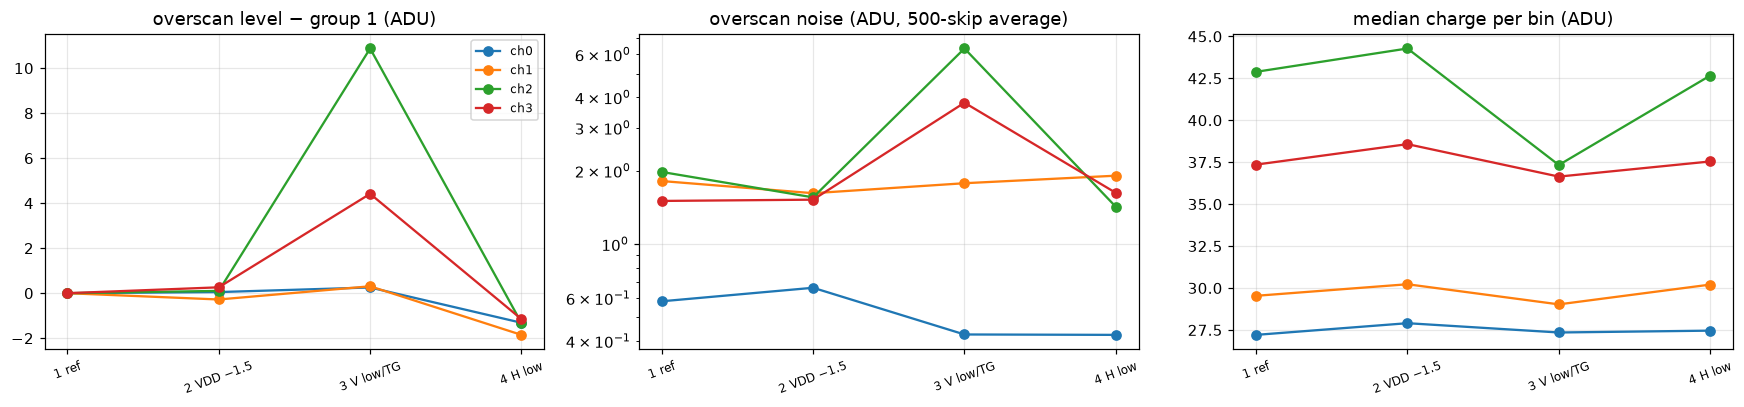

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ch in range(4):
    sel = sorted([r for r in rows if r["ch"] == ch], key=lambda r: r["group"])
    gs = [r["group"] for r in sel]
    axes[0].plot(gs, [r["level"] - sel[0]["level"] for r in sel], "o-", label=f"ch{ch}")
    axes[1].plot(gs, [r["noise"] for r in sel], "o-", label=f"ch{ch}")
    axes[2].plot(gs, [r["charge"] for r in sel], "o-", label=f"ch{ch}")
for ax, title in zip(axes, ["overscan level − group 1 (ADU)", "overscan noise (ADU, 500-skip average)", "median charge per bin (ADU)"]):
    ax.set_xticks(sorted(images)); ax.set_xticklabels([LABEL[g] for g in sorted(images)], rotation=20, fontsize=8); ax.set_title(title)
axes[1].set_yscale("log"); axes[0].legend(fontsize=8)
plt.tight_layout(); save(fig, "image_overscan"); plt.show()

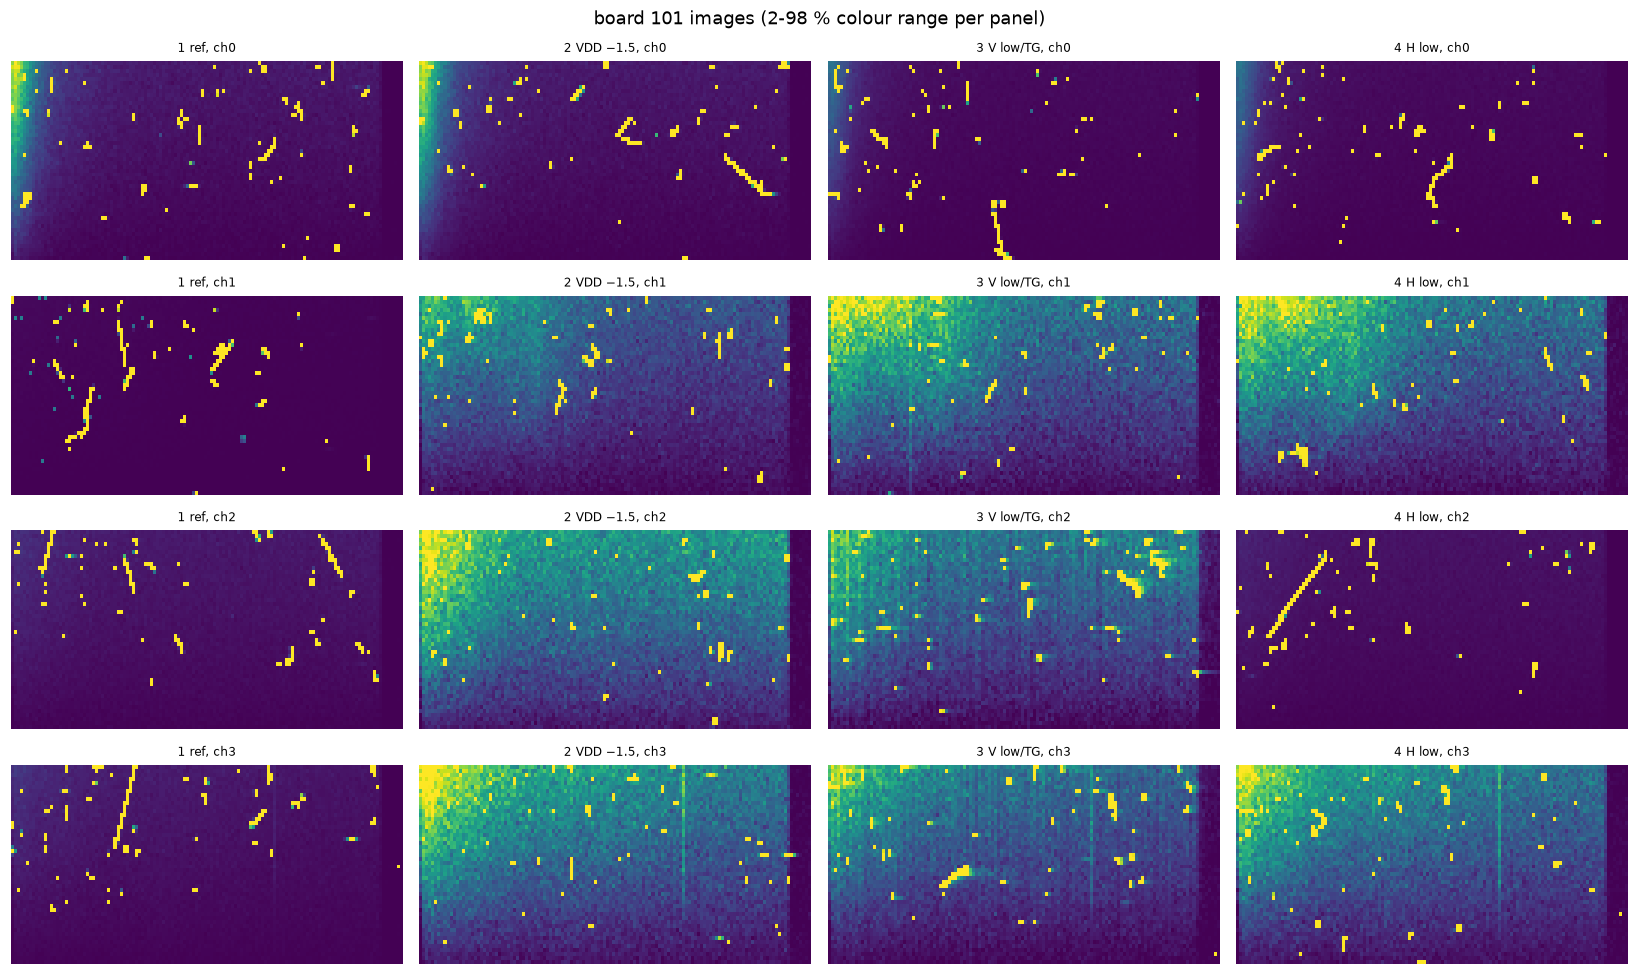

In [16]:
fig, axes = plt.subplots(4, 4, figsize=(15, 9))
for row, ch in enumerate(range(4)):
    for col, g in enumerate(sorted(images)):
        d = images[g][ch + 1].data.astype(float)
        lo, hi = np.percentile(d, [2, 98])
        axes[row, col].imshow(d, origin="lower", aspect="auto", vmin=lo, vmax=hi, cmap="viridis")
        axes[row, col].set_title(f"{LABEL[g]}, ch{ch}", fontsize=8); axes[row, col].axis("off")
fig.suptitle("board 101 images (2-98 % colour range per panel)")
plt.tight_layout(); save(fig, "images"); plt.show()

* **Group 3 (vertical/TG, with TG_B high below low on board 101) raises the overscan level and noise
  only on channels 2 and 3** (amplifiers A and B). The traces of channel 2 show the same: more
  noise. The trace and the image agree.
* **Group 4 (horizontal low rails) lowers the overscan level of all channels** by 1.2–1.9 ADU. The
  traces show a matching baseline shift.
* The charge per bin is nearly the same in every setting on channels 0 and 1. On channels 2 and 3 it is
  lower in group 3 (by 5.6 and 0.7 ADU), together with the higher overscan level: it is measured
  relative to the overscan, so this may be an offset change rather than less charge.
* Board 102 (not shown): channels 0, 1 and 3 hold no charge; only channel 2 does.

## 9. Trace against image: channel 2 noise

The noisiest amplifier gives the clearest link between a trace feature and an image quantity. For
each setting with an image: the trace's CDS noise per skip against the image's overscan noise.

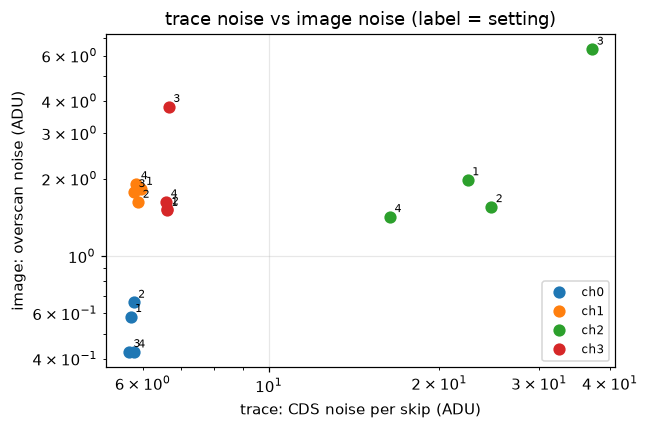

In [17]:
fig, ax = plt.subplots(figsize=(6, 4))
for ch in range(4):
    xs, ys = [], []
    for g in sorted(images):
        r = next(r for r in rows if r["group"] == g and r["ch"] == ch)
        xs.append(np.nanmean(values(g, ch, "skip: CDS rms (detrended)"))); ys.append(r["noise"])
    ax.plot(xs, ys, "o", label=f"ch{ch}", ms=7)
    for g, x, y in zip(sorted(images), xs, ys):
        ax.annotate(str(g), (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xscale="log", yscale="log", xlabel="trace: CDS noise per skip (ADU)", ylabel="image: overscan noise (ADU)",
       title="trace noise vs image noise (label = setting)")
ax.legend(fontsize=8); plt.tight_layout(); save(fig, "trace_vs_image_noise"); plt.show()

The channels sort in the same order in the trace and in the image, and channel 2's jump in group 3
appears in both. With 4 images this is an illustration, not a calibration: the relation between trace
features and image labels is what the training data must establish.

## 10. Summary

| Parameter changed | What the traces show | What the images show |
|---|---|---|
| VDD −19 → −20.5 V (group 2; back to −19 in groups 3–5) | slower amplifier response on every channel (settling and dip-recovery times up about 0.008–0.012 µs, and back down by the same amount in groups 3–5), pulse peak +about 480 ADU | small changes |
| vertical low rails −0.5 V, TG 7.4 → 7.0 V (group 3) | vertical-transfer waveform about 6,000 ADU deeper on all channels; channel 2 noise 22 → 37 ADU per skip | overscan level and noise up on channels 2 and 3 (A, B) only |
| all horizontal low rails −0.5 V (group 4) | horizontal-transfer waveform about 15,000 ADU deeper; baseline about 2,700 ADU lower | overscan level 1.2–1.9 ADU lower on all channels |
| only H3_A_L −0.5 V (group 5) | about half of the group 4 effect on the horizontal transfer and baseline | (no image) |

Caveats:

* group 1 traces used a different trace setup (`NCOLPRE` 0 instead of the inherited 185);
* 3 trace sets per setting is a small sample;
* VDD returned to −19 V after group 2, so comparisons of group 2 with groups 3–5 mix two changes;
* the settings were taken up to 85 minutes apart, so drift is mixed into every comparison;
* the group 3 TG_B setting was inverted on board 101.

**For the next run:** set all cuts in the traces; take reference traces in every packet and repeat the
reference at the end; and take a 1×1 image that WADERs can fit (see the recommendation in the session
notes: 35 rows × 1000 columns × 200 skips, about 4.9 min).